<a href="https://colab.research.google.com/github/shalomp20/cooking-helper-api/blob/main/drowning_synth.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# סט בדיקה סינתטי – זיהוי טביעות בים ממצלמה קדמית על גג סוכת מציל
**לפני הכול:** Runtime → Change runtime type → **T4 GPU**. מריצים תא-תא לפי הסדר.

**השינוי המרכזי בגרסה הזו:** הפרומפט לבדו לא מצליח לשלוט בגובה, בזווית וביחס ים/חוף (ראינו ב-v1). לכן **הקומפוזיציה נקבעת בגאומטריה ולא במילים**:
1. מגדירים מצלמה פיזית: גובה, שדה ראייה, מרחק לקו המים → מחשבים הטיה, שורת אופק ושורת קו חוף.
2. מזה בונים **מפת עומק** (ControlNet Depth) – מכתיבה את הפרספקטיבה של מצלמה בגובה 6 מ'.
3. ו**תמונת פריסה** (שמיים / ים / חול בצבעים גסים) – נקודת התחלה ל-img2img שמכתיבה את היחס ים/חוף.
4. הפרומפט אחראי רק על **מרקם**: מצב הים והתאורה.

זה בדיוק צעד 9 במדריך של אפרטסין: הכוונת תמונות באמצעות **אות בקרה**.

| חלק | מה קורה |
|---|---|
| 1 | הגדרות: מצלמה, מטריצת ניסוי, פרומפטים |
| 2 | גאומטריה: מפת עומק + תמונת פריסה (בלי GPU) |
| 3 | SDXL + ControlNet Depth: מעבדת פרומפטים → ייצור רקעים + סינון |
| 4 | אימות: SegFormer בודק שהים באמת איפה שתכננו |
| 5 | תנוחות (OpenPose) |
| 6 | הוספת אנשים במרחקים אמיתיים במטרים → bbox (SAM) → תוויות + לוג |
| 7 | בדיקה ידנית + איזון |
| 8 | הערכת המודל |

In [1]:
!pip install -q diffusers transformers accelerate ultralytics

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. הגדרות
`CLASS_MAP` חייב להתאים ל-`model.names` של המודל שתבדקו (חלק 8) – לעדכן **לפני** חלק 6.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, csv, gc
import numpy as np
from PIL import Image, ImageDraw, ImageFilter
from IPython.display import display

BASE = '/content/drive/MyDrive/GENAI_project'     # ← Copy path מהשלב הראשון

STAGES = {                               # מפתח בקוד ← שם התיקייה ב-Drive
    'prompt_lab':  '/content/drive/MyDrive/GENAI_project/prompt_lab',          # ניסויי ניסוח (גרידים)
    'controls':    '/content/drive/MyDrive/GENAI_project/controls',            # תמונות פריסה + מפות עומק
    'backgrounds': '/content/drive/MyDrive/GENAI_project/backgrounds',         # רקעים שעברו
    'bg_rejected': '/content/drive/MyDrive/GENAI_project/bg_rejected',# רקעים שנפסלו (נמצאו אנשים)
    'masks':       '/content/drive/MyDrive/GENAI_project/masks',         # מסכות ים (SegFormer)
    'images':      '/content/drive/MyDrive/GENAI_project/images',         # תמונות סופיות עם אנשים
    'labels':      '/content/drive/MyDrive/GENAI_project/labels',         # תוויות YOLO
    'review':      '/content/drive/MyDrive/GENAI_project/review',              # תמונות בדיקה עם תיבות
    'meta':        '/content/drive/MyDrive/GENAI_project/meta',                # JSON / CSV: לוג של הכול
}
DIRS = {k: os.path.join(BASE, v) for k, v in STAGES.items()}
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)
print('\n'.join(sorted(os.listdir(BASE))))
for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

W, H = 1344, 768
SEED0 = 1000
BGS_PER_COMBO = 2            # פיילוט: 3 ים × 3 תאורה × 2 = 18 רקעים

# ---- מצלמה (פרונט, ניצבת לים) ----
CAM_HEIGHT_M = 6.0           # גובה מעל פני הים (הערכה – לעדכן לפי מדידה). סטייה: ±5 ס"מ
HFOV_DEG = 40                # שדה ראייה אופקי (עדשה)
SKY_FRAC = 0.08              # כמה מהתמונה שמיים (קובע את הטיית המצלמה)
SHORE_DIST_M = 20.0          # מרחק אופקי מהמצלמה לקו המים (קובע כמה חול רואים)
# עם הערכים האלה: ~71% ים, ~21% חול, ~8% שמיים
JITTER = dict(h=0.05, tilt_deg=0.7, shore=3.0)   # שונות בין רקעים

H_VIS_M = 0.5                # גובה "ראש+כתפיים" מעל המים – יחידת הגודל של אדם
DIST_BANDS = {'near': (2, 15), 'mid': (15, 40), 'far': (40, 80)}   # מטרים מקו המים לתוך הים
MIN_PX = 8                   # אדם קטן מזה לא מייצרים

CLASS_MAP = {'drowning': 0, 'swimming': 1}   # להתאים ל-model.names!

# ---- מטריצת ניסוי + פרומפטים (נבדקו ≤ 77 טוקנים) ----
SEA = {
    'calm': 'calm sea, small ripples',
    'waves': 'moderate waves, white foam',
    'rough': 'rough sea, large breaking waves',
}
LIGHT = {
    'glare': 'harsh midday sun, glare on the water',
    'overcast': 'overcast soft light',
    'golden': 'golden hour, low sun',
}
BG_PROMPT = ("Sharp DSLR photo of the open Mediterranean sea from a slightly elevated viewpoint on the beach, "
             "clear horizon and sky at the top, {sea}, {light}, detailed wave texture, "
             "waves get smaller toward the horizon, thin strip of empty sand at the bottom, no people, photorealistic")
BG_NEG = ("aerial view, top-down view, drone shot, no horizon, long exposure, motion blur, smooth water, "
          "soft focus, abstract, painting, camera, device, pole, object, people, person, swimmer, "
          "lifeguard tower, hut, building, pier, boat, umbrella, text, watermark, cartoon, blurry")
def check_tokens(tokenizer, text, tag=''):
    nt = len(tokenizer(text).input_ids)          # כולל טוקני התחלה/סוף; CLIP קורא עד 77
    if nt > 77:
        print(f'⚠️ {tag}: {nt} טוקנים – הסוף ייחתך! לקצר את הפרומפט')
    return nt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
backgrounds
bg_rejected
controls
drowning_synth.ipynb
images
labels
masks
meta
prompt_lab
review


## 2. גאומטריה: מצלמת חריר מעל מישור הים
מצלמה בגובה $h$, מוטה כלפי מטה בזווית $\theta$, מרחק מוקד $f=\frac{W/2}{\tan(\text{HFOV}/2)}$.
נקודה במרחק אופקי $D$ ובגובה $z$ נופלת בשורה:
$$y = \tfrac{H}{2} + f\cdot\tan\!\Big(\arctan\tfrac{h-z}{D} - \theta\Big)$$
- **אופק** ($D\to\infty$): $y_h = H/2 - f\tan\theta$ → מזה מחשבים את $\theta$ לפי `SKY_FRAC`.
- **קו חוף**: $D$ = `SHORE_DIST_M`.
- **גודל אדם** במרחק $D$: $y(D,0) - y(D, z)$ – מדויק, לא קירוב.

h=6.00m tilt=9.9° shore=20.0m | sky 8%  sea 71%  sand 21%
  near   2m מקו המים (D=22m): ראש+כתפיים = 40px
  near  15m מקו המים (D=35m): ראש+כתפיים = 26px
  mid   15m מקו המים (D=35m): ראש+כתפיים = 26px
  mid   40m מקו המים (D=60m): ראש+כתפיים = 15px
  far   40m מקו המים (D=60m): ראש+כתפיים = 15px
  far   80m מקו המים (D=100m): ראש+כתפיים = 9px


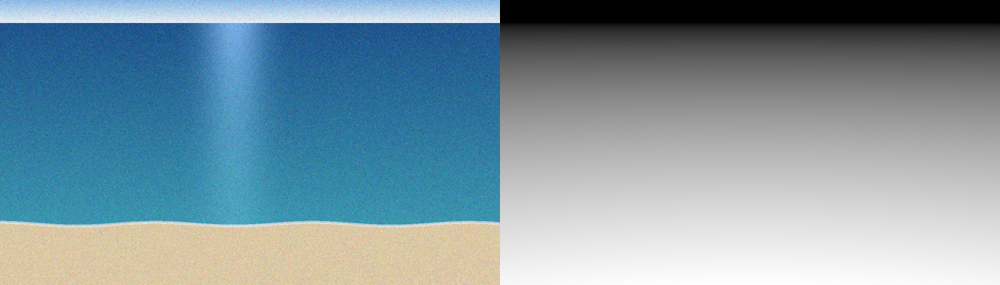

In [4]:
F_PX = (W / 2) / np.tan(np.radians(HFOV_DEG / 2))
BASE_TILT = float(np.degrees(np.arctan((H / 2 - SKY_FRAC * H) / F_PX)))

def make_cam(rng=None):
    if rng is None:
        return dict(h=CAM_HEIGHT_M, tilt=BASE_TILT, shore=SHORE_DIST_M)
    return dict(h=CAM_HEIGHT_M + rng.uniform(-JITTER['h'], JITTER['h']),
                tilt=BASE_TILT + rng.uniform(-JITTER['tilt_deg'], JITTER['tilt_deg']),
                shore=SHORE_DIST_M + rng.uniform(-JITTER['shore'], JITTER['shore']))

def row_of(D, z, cam):
    beta = np.arctan2(cam['h'] - z, D)
    return H / 2 + F_PX * np.tan(beta - np.radians(cam['tilt']))

def horizon_row(cam):
    return H / 2 - F_PX * np.tan(np.radians(cam['tilt']))

def shore_row(cam):
    return row_of(cam['shore'], 0, cam)

def depth_map(cam):
    """מפת עומק (קרוב=לבן) של מישור שטוח בגובה 0, כפי שהמצלמה רואה אותו."""
    xs = (np.arange(W) - W / 2) / F_PX
    ys = (np.arange(H) - H / 2) / F_PX
    X, Y = np.meshgrid(xs, ys)
    th = np.radians(cam['tilt'])
    down = Y * np.cos(th) + np.sin(th)          # רכיב הקרן כלפי מטה בעולם
    norm = np.sqrt(X**2 + Y**2 + 1)
    with np.errstate(divide='ignore', invalid='ignore'):
        slant = np.where(down > 1e-4, cam['h'] / down * norm, np.inf)
    disp = np.nan_to_num(1 / slant)
    disp = (disp / disp.max()) ** 0.5            # גאמא – לפרוש את הערכים
    return Image.fromarray((disp * 255).astype(np.uint8)).convert('RGB')

PALETTE = {
    'glare':    dict(sky_top=(140, 185, 230), sky_bot=(230, 238, 245), sea_far=(30, 85, 140),
                     sea_near=(60, 150, 175), sand=(220, 200, 165), sun=True),
    'overcast': dict(sky_top=(165, 170, 180), sky_bot=(205, 208, 212), sea_far=(65, 85, 100),
                     sea_near=(95, 120, 130), sand=(185, 175, 155), sun=False),
    'golden':   dict(sky_top=(110, 130, 185), sky_bot=(250, 185, 125), sea_far=(55, 75, 115),
                     sea_near=(150, 120, 100), sand=(215, 165, 115), sun=True),
}

def layout_image(cam, light, rng):
    """תמונת פריסה גסה: שמיים / ים / קצף / חול – נקודת התחלה ל-img2img."""
    pal = PALETTE[light]
    y_h, y_s = horizon_row(cam), shore_row(cam)
    Y, X = np.mgrid[0:H, 0:W].astype(float)
    shore = y_s + 5 * np.sin(X / W * 2 * np.pi * rng.uniform(1.5, 3.5) + rng.uniform(0, 6.28))
    lerp = lambda a, b, t: np.array(a)[None, None] * (1 - t[..., None]) + np.array(b)[None, None] * t[..., None]
    t_sky = np.clip(Y / max(y_h, 1), 0, 1)
    t_sea = np.clip((Y - y_h) / max(y_s - y_h, 1), 0, 1)
    arr = np.where((Y < y_h)[..., None], lerp(pal['sky_top'], pal['sky_bot'], t_sky),
                   lerp(pal['sea_far'], pal['sea_near'], t_sea))
    arr = np.where((Y >= shore)[..., None], np.array(pal['sand'])[None, None], arr)
    foam = np.abs(Y - shore) < 4
    arr[foam] = arr[foam] * 0.3 + 230 * 0.7
    if pal['sun']:                                   # פס בוהק על המים
        cx = W * rng.uniform(0.3, 0.7)
        streak = np.exp(-((X - cx) / (W * 0.06)) ** 2) * (Y > y_h) * (Y < shore) * np.exp(-(Y - y_h) / (H * 0.4))
        arr = arr + streak[..., None] * 90
    arr = arr + rng_np(rng).normal(0, 22, arr.shape)                     # היה 10
    img = Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8))
    return img                                                            # בלי GaussianBlur

def rng_np(rng):
    return np.random.default_rng(rng.randint(0, 2**31))

def describe(cam):
    y_h, y_s = horizon_row(cam), shore_row(cam)
    return (f"h={cam['h']:.2f}m tilt={cam['tilt']:.1f}° shore={cam['shore']:.1f}m | "
            f"sky {y_h/H:.0%}  sea {(y_s-y_h)/H:.0%}  sand {(H-y_s)/H:.0%}")

# תצוגה: מצלמת הבסיס
cam0 = make_cam()
print(describe(cam0))
for band, (a, b) in DIST_BANDS.items():
    for off in (a, b):
        D = cam0['shore'] + off
        print(f"  {band:4s} {off:3d}m מקו המים (D={D:.0f}m): ראש+כתפיים = {row_of(D,0,cam0)-row_of(D,H_VIS_M,cam0):.0f}px")
lay0 = layout_image(cam0, 'glare', random.Random(0))
dep0 = depth_map(cam0)
pair = Image.new('RGB', (W, H // 2)); pair.paste(lay0.resize((W // 2, H // 2)), (0, 0)); pair.paste(dep0.resize((W // 2, H // 2)), (W // 2, 0))
display(pair)   # שמאל: פריסה, ימין: מפת עומק

## 3. SDXL + ControlNet Depth (img2img)
- `STRENGTH` – כמה מותר למודל לשנות את תמונת הפריסה (1.0 = מתעלם ממנה; 0.5 = נשאר קרוב מדי לפריסה הגסה).
- `CN_DEPTH_SCALE` – כמה חזק להיצמד לפרספקטיבה של מפת העומק.

VAE מיוחד (`sdxl-vae-fp16-fix`) – בלעדיו SDXL ב-fp16 מייצר לפעמים תמונות שחורות. הורדה ראשונה ~10GB.

In [5]:
import torch
from diffusers import StableDiffusionXLControlNetImg2ImgPipeline, ControlNetModel, AutoencoderKL

vae = AutoencoderKL.from_pretrained('madebyollin/sdxl-vae-fp16-fix', torch_dtype=torch.float16)
cn_depth = ControlNetModel.from_pretrained('diffusers/controlnet-depth-sdxl-1.0-small',
                                           torch_dtype=torch.float16, use_safetensors=True)
pipe = StableDiffusionXLControlNetImg2ImgPipeline.from_pretrained(
    'stabilityai/stable-diffusion-xl-base-1.0', controlnet=cn_depth,
    vae=vae, torch_dtype=torch.float16, variant='fp16', use_safetensors=True
).to('cuda')                      # הכול ב-GPU, בלי cpu_offload
pipe.vae.enable_tiling()          # מפחית זיכרון בפענוח התמונהgc.collect(); torch.cuda.empty_cache()
print(f'GPU: {torch.cuda.memory_allocated()/1e9:.1f}GB בשימוש')

STRENGTH = 0.85
CN_DEPTH_SCALE = 0.5

def gen_background(prompt, cam, light, seed):
    rng = random.Random(seed)
    layout, depth = layout_image(cam, light, rng), depth_map(cam)
    g = torch.Generator('cuda').manual_seed(seed)
    with torch.inference_mode():
        img = pipe(prompt=prompt, negative_prompt=BG_NEG, image=layout, control_image=depth,
                   strength=STRENGTH, controlnet_conditioning_scale=CN_DEPTH_SCALE,
                   num_inference_steps=30, guidance_scale=6.0, generator=g).images[0]
    gc.collect(); torch.cuda.empty_cache()
    return img, layout, depth

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

GPU: 7.4GB בשימוש


In [6]:
STRENGTH = 0.93
CN_DEPTH_SCALE = 0.75


### מעבדת פרומפטים
אותם seeds ואותה מצלמה בכל גרסה → ההבדל בין v1 ל-v2 נובע **רק** ממה ששיניתם (ניסוח, `STRENGTH`, `CN_DEPTH_SCALE`).
שורות = תאורה, עמודות = seeds. הכול נשמר ב-`prompt_lab/<גרסה>/` כולל `settings.json`.

h=6.00m tilt=9.9° shore=20.0m | sky 8%  sea 71%  sand 21%
glare: 67/77 טוקנים


  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

overcast: 62/77 טוקנים


  0%|          | 0/27 [00:00<?, ?it/s]

... (2 outputs left out)

golden: 64/77 טוקנים


  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

  0%|          | 0/27 [00:00<?, ?it/s]

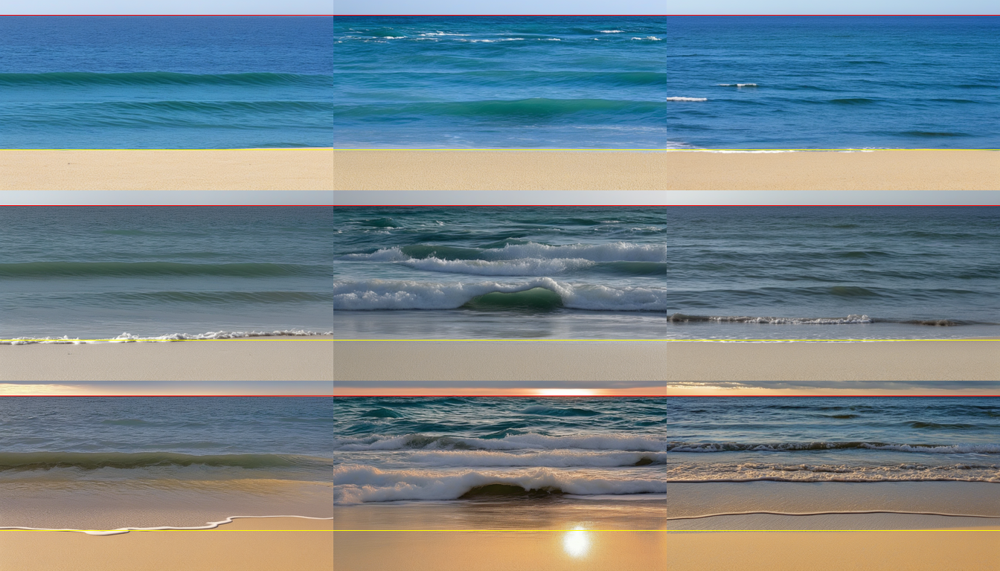

In [7]:
LAB_VERSION = 'v1'
LAB_SEEDS = [11, 22, 33]
LAB_SEA = 'waves'

lab_dir = os.path.join(DIRS['prompt_lab'], LAB_VERSION)
os.makedirs(lab_dir, exist_ok=True)
cam = make_cam()
print(describe(cam))
log = []
for light in LIGHT:
    prompt = BG_PROMPT.format(sea=SEA[LAB_SEA], light=LIGHT[light])
    print(f'{light}: {check_tokens(pipe.tokenizer, prompt, light)}/77 טוקנים')
    for s in LAB_SEEDS:
        img, layout, depth = gen_background(prompt, cam, light, s)
        fn = f'{light}_s{s}.png'
        img.save(os.path.join(lab_dir, fn))
        log.append({'file': fn, 'light': light, 'seed': s, 'prompt': prompt})
layout.save(os.path.join(lab_dir, 'example_layout.png')); depth.save(os.path.join(lab_dir, 'depth.png'))

with open(os.path.join(lab_dir, 'settings.json'), 'w') as f:
    json.dump({'negative': BG_NEG, 'sea': LAB_SEA, 'strength': STRENGTH, 'cn_depth_scale': CN_DEPTH_SCALE,
               'cam': cam, 'hfov': HFOV_DEG, 'items': log}, f, indent=2, ensure_ascii=False)

tw, th = 448, 256
grid = Image.new('RGB', (tw * len(LAB_SEEDS), th * len(LIGHT)))
for i, l in enumerate(log):
    t = Image.open(os.path.join(lab_dir, l['file'])).resize((tw, th))
    d = ImageDraw.Draw(t)                    # קווי ייחוס: אופק וקו חוף מתוכננים
    d.line([(0, horizon_row(cam) * th / H), (tw, horizon_row(cam) * th / H)], fill='red', width=1)
    d.line([(0, shore_row(cam) * th / H), (tw, shore_row(cam) * th / H)], fill='yellow', width=1)
    grid.paste(t, ((i % len(LAB_SEEDS)) * tw, (i // len(LAB_SEEDS)) * th))
grid.save(os.path.join(lab_dir, 'grid.jpg'))
display(grid)   # אדום = אופק מתוכנן, צהוב = קו חוף מתוכנן

### ייצור רקעים + סינון
לכל רקע מצלמה עם שונות קטנה (`JITTER`). כל רקע נשמר: עובר → `backgrounds/`, נפסל → `bg_rejected/`. הפריסה ומפת העומק → `controls/`. פרמטרי המצלמה → `meta/backgrounds.json`.

In [8]:
STRENGTH = 0.93
CN_DEPTH_SCALE = 0.75

In [9]:
from ultralytics import YOLO
person_det = YOLO('yolo11n.pt')

def count_people(img, conf=0.25):
    r = person_det.predict(img, classes=[0], conf=conf, verbose=False)[0]
    return len(r.boxes)

meta_path = os.path.join(DIRS['meta'], 'backgrounds.json')
bg_meta = json.load(open(meta_path)) if os.path.exists(meta_path) else {}
PILOT_COMBOS = [('calm', 'glare'), ('waves', 'overcast'), ('rough', 'golden')]
BGS_PER_COMBO = 1
seed = SEED0 + 10 * len(bg_meta)
for sea_k, light_k in PILOT_COMBOS:
    sea_txt, light_txt = SEA[sea_k], LIGHT[light_k]
    if True:      # שומר על ההזחה של שאר הקוד, כדי שלא תצטרכו להזיז שורות
        prompt = BG_PROMPT.format(sea=sea_txt, light=light_txt)
        check_tokens(pipe.tokenizer, prompt, f'{sea_k}/{light_k}')
        made, tries = 0, 0
        while made < BGS_PER_COMBO and tries < BGS_PER_COMBO * 3:
            tries += 1
            seed += 1
            cam = make_cam(random.Random(seed))
            img, layout, depth = gen_background(prompt, cam, light_k, seed)
            name = f'bg_s{seed}_{sea_k}_{light_k}.png'
            if count_people(img) > 0:
                img.save(os.path.join(DIRS['bg_rejected'], name))
                print('נפסל (נמצאו אנשים):', name)
                continue
            img.save(os.path.join(DIRS['backgrounds'], name))
            layout.save(os.path.join(DIRS['controls'], name.replace('bg_', 'layout_')))
            bg_meta[name] = dict(seed=seed, sea=sea_k, light=light_k, cam=cam, prompt=prompt,
                                 strength=STRENGTH, cn_depth_scale=CN_DEPTH_SCALE)
            with open(meta_path, 'w') as f:
                json.dump(bg_meta, f, indent=2)
            made += 1
            print('נשמר:', name, '|', describe(cam))

  0%|          | 0/27 [00:00<?, ?it/s]

נשמר: bg_s1001_calm_glare.png | h=6.03m tilt=9.3° shore=21.6m | sky 11%  sea 66%  sand 23%


  0%|          | 0/27 [00:00<?, ?it/s]

נשמר: bg_s1002_waves_overcast.png | h=6.00m tilt=9.8° shore=18.3m | sky 8%  sea 77%  sand 15%


  0%|          | 0/27 [00:00<?, ?it/s]

נשמר: bg_s1003_rough_golden.png | h=6.00m tilt=9.7° shore=21.3m | sky 9%  sea 66%  sand 25%


bg_s1001_calm_glare.png


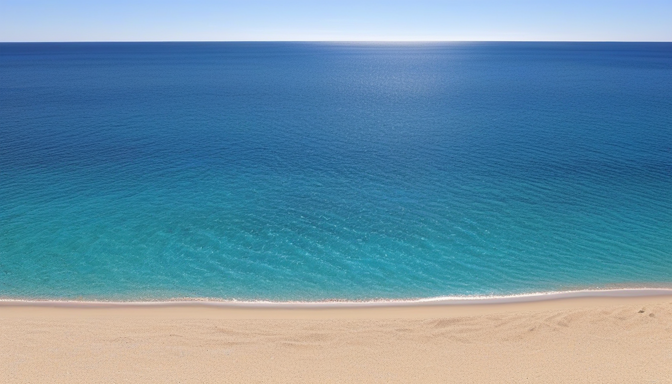

bg_s1002_waves_overcast.png


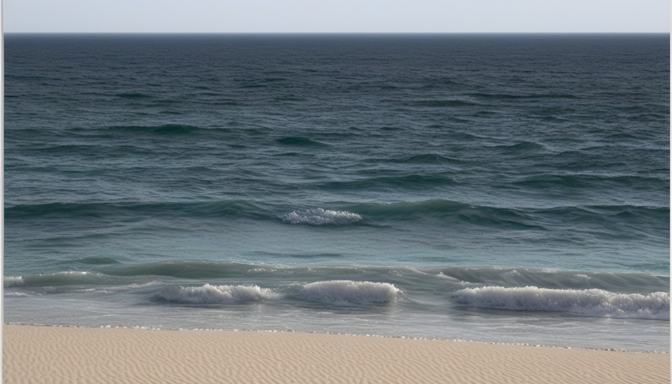

bg_s1003_rough_golden.png


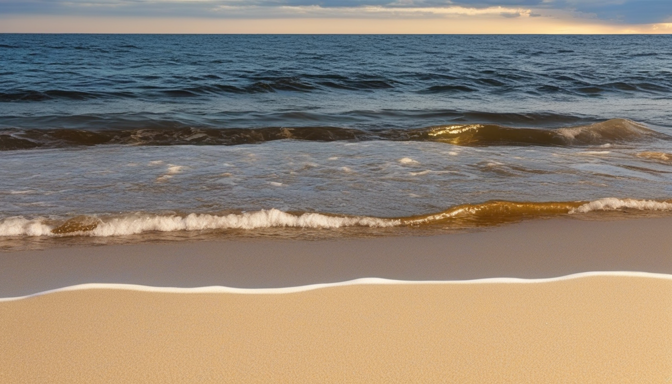

In [10]:
# בדיקה בעין: רקע לא טוב – מחקו אותו מ-backgrounds/ ב-Drive
for f in sorted(os.listdir(DIRS['backgrounds'])):
    print(f)
    display(Image.open(os.path.join(DIRS['backgrounds'], f)).resize((672, 384)))

## 4. אימות: האם הים באמת איפה שתכננו?
SegFormer (ADE20K) מסמן ים בכל רקע. משווים ל**גאומטריה המתוכננת**: אחוז ים, ושורת האופק. רקע שסוטה הרבה → המודל לא כיבד את הבקרה → לשקול למחוק.
מסכת הים משמשת אחר כך כדי לשים אנשים **רק במים**.

In [11]:
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
SEG_ID = 'nvidia/segformer-b2-finetuned-ade-512-512'
seg_proc = SegformerImageProcessor.from_pretrained(SEG_ID)
seg_model = SegformerForSemanticSegmentation.from_pretrained(SEG_ID).to('cuda').eval()
WATER_IDS = [int(i) for i, nm in seg_model.config.id2label.items() if nm in ('sea', 'water', 'lake', 'river')]

@torch.no_grad()
def water_mask(img):
    inp = seg_proc(images=img, return_tensors='pt').to('cuda')
    logits = seg_model(**inp).logits
    up = torch.nn.functional.interpolate(logits, size=(img.height, img.width), mode='bilinear', align_corners=False)
    return np.isin(up.argmax(1)[0].cpu().numpy(), WATER_IDS)

bg_meta = json.load(open(os.path.join(DIRS['meta'], 'backgrounds.json')))
rows = []
for f in sorted(os.listdir(DIRS['backgrounds'])):
    if f not in bg_meta:
        continue
    cam = bg_meta[f]['cam']
    wm = water_mask(Image.open(os.path.join(DIRS['backgrounds'], f)).convert('RGB'))
    Image.fromarray((wm * 255).astype(np.uint8)).save(os.path.join(DIRS['masks'], f))
    top = np.where(wm.mean(1) > 0.3)[0]
    det_h = int(top[0]) if len(top) else -1
    plan_sea = (shore_row(cam) - horizon_row(cam)) / H
    rows.append(dict(file=f, plan_sea=round(plan_sea, 2), seg_sea=round(float(wm.mean()), 2),
                     plan_horizon=int(horizon_row(cam)), seg_horizon=det_h))
    bg_meta[f]['seg_sea'] = float(wm.mean()); bg_meta[f]['seg_horizon'] = det_h
with open(os.path.join(DIRS['meta'], 'backgrounds.json'), 'w') as fj:
    json.dump(bg_meta, fj, indent=2)

import pandas as pd
chk = pd.DataFrame(rows)
chk['sea_err'] = (chk.seg_sea - chk.plan_sea).abs()
chk['horizon_err_px'] = (chk.seg_horizon - chk.plan_horizon).abs()
chk['flag'] = np.where((chk.sea_err > 0.15) | (chk.horizon_err_px > 0.06 * H), '⚠️', '')
print(chk.to_string(index=False))
print(f'\nממוצע: ים מתוכנן {chk.plan_sea.mean():.0%} | ים בפועל {chk.seg_sea.mean():.0%}')

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

                       file  plan_sea  seg_sea  plan_horizon  seg_horizon  sea_err  horizon_err_px flag
    bg_s1001_calm_glare.png      0.66     0.67            81           84     0.01               3     
bg_s1002_waves_overcast.png      0.77     0.79            65           65     0.02               0     
  bg_s1003_rough_golden.png      0.66     0.57            67           67     0.09               0     

ממוצע: ים מתוכנן 70% | ים בפועל 68%


## 5. תנוחות (שלדי OpenPose)
18 נקודות מפתח בפורמט OpenPose, יחסיות לתיבת האדם (0..1). `None` = מתחת למים.
`h_mult` = גובה התיבה ביחידות של `H_VIS_M` (0.5 מ'). `waving` הוא **hard negative** – מתויג swimming.

0 drowning_idr → drowning
1 drowning_handsup → drowning
2 swimming → swimming
3 waving → swimming


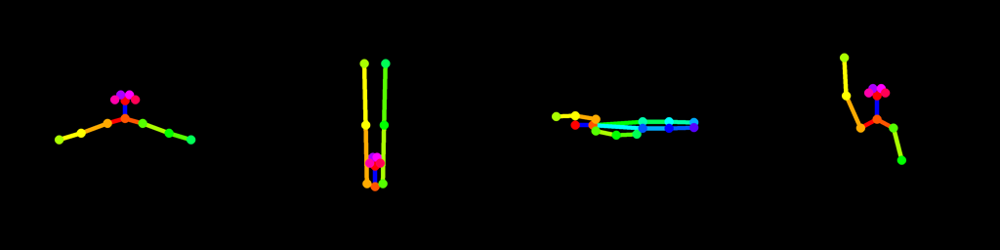

In [12]:
# 0 Nose,1 Neck,2 RSho,3 RElb,4 RWri,5 LSho,6 LElb,7 LWri,8 RHip,9 RKnee,10 RAnk,
# 11 LHip,12 LKnee,13 LAnk,14 REye,15 LEye,16 REar,17 LEar
def kp(**pts):
    k = [None] * 18
    for i, p in pts.items():
        k[int(i[1:])] = p
    return k

SUFFIX = ', seen from a high camera, {sea}, {light}, matching scene lighting, photorealistic'
PERSON_NEG = 'multiple people, crowd, extra limbs, deformed body, floating above water, sharp cutout edges, sticker, different lighting, cartoon, text'

POSES = {
    'drowning_idr': dict(label='drowning', weight=0.25, aspect=1.8, h_mult=1.0,
        prompt='a person drowning in the sea, upright in the water, only head and shoulders above the surface, head tilted back, mouth at water level, arms spread sideways pressing on the water, splashes',
        kps=kp(k0=(.50,.20), k1=(.50,.42), k2=(.38,.48), k3=(.20,.60), k4=(.05,.68),
               k5=(.62,.48), k6=(.80,.60), k7=(.95,.68),
               k14=(.47,.13), k15=(.53,.13), k16=(.43,.19), k17=(.57,.19))),
    'drowning_handsup': dict(label='drowning', weight=0.25, aspect=0.45, h_mult=1.8,
        prompt='a person drowning in the sea, head barely above the water, both arms raised straight up, struggling, splashes',
        kps=kp(k0=(.50,.78), k1=(.50,.92), k2=(.38,.90), k3=(.36,.50), k4=(.34,.08),
               k5=(.62,.90), k6=(.64,.50), k7=(.66,.08),
               k14=(.47,.72), k15=(.53,.72), k16=(.42,.76), k17=(.58,.76))),
    'swimming': dict(label='swimming', weight=0.30, aspect=3.5, h_mult=0.6,
        prompt='a person swimming freestyle in the sea, body horizontal, face in the water, one arm mid-stroke, small white wake',
        kps=kp(k0=(.16,.50), k1=(.28,.50), k2=(.30,.36), k3=(.16,.28), k4=(.03,.30),
               k5=(.30,.64), k6=(.44,.74), k7=(.58,.72),
               k8=(.62,.42), k9=(.80,.42), k10=(.97,.44), k11=(.62,.58), k12=(.80,.58), k13=(.97,.56))),
    'waving': dict(label='swimming', weight=0.20, aspect=0.7, h_mult=1.8,
        prompt='a happy person standing in chest-deep sea water, smiling, waving one arm toward the shore',
        kps=kp(k0=(.52,.30), k1=(.52,.46), k2=(.36,.52), k3=(.22,.30), k4=(.20,.04),
               k5=(.68,.52), k6=(.76,.74),
               k14=(.48,.25), k15=(.56,.25), k16=(.44,.28), k17=(.60,.28))),
}
POSE_KEYS = list(POSES)
POSE_W = [POSES[k]['weight'] for k in POSE_KEYS]

LIMBS = [(1,2),(1,5),(2,3),(3,4),(5,6),(6,7),(1,8),(8,9),(9,10),(1,11),(11,12),(12,13),
         (1,0),(0,14),(14,16),(0,15),(15,17)]
COLORS = [(255,0,0),(255,85,0),(255,170,0),(255,255,0),(170,255,0),(85,255,0),(0,255,0),(0,255,85),
          (0,255,170),(0,255,255),(0,170,255),(0,85,255),(0,0,255),(85,0,255),(170,0,255),(255,0,255),
          (255,0,170),(255,0,85)]
FLIP_PAIRS = [(2,5),(3,6),(4,7),(8,11),(9,12),(10,13),(14,15),(16,17)]

def jitter(kps, rng, amt=0.03):
    return [None if p is None else (p[0] + rng.uniform(-amt, amt), p[1] + rng.uniform(-amt, amt)) for p in kps]

def flip(kps):
    k = [None if p is None else (1 - p[0], p[1]) for p in kps]
    for a, b in FLIP_PAIRS:
        k[a], k[b] = k[b], k[a]
    return k

def draw_pose(kps, box, size=1024):
    canvas = Image.new('RGB', (size, size), 'black')
    d = ImageDraw.Draw(canvas)
    x0, y0, x1, y1 = box
    pts = [None if p is None else (x0 + p[0] * (x1 - x0), y0 + p[1] * (y1 - y0)) for p in kps]
    lw = max(4, int(max(x1 - x0, y1 - y0) * 0.03))
    for i, (a, b) in enumerate(LIMBS):
        if pts[a] and pts[b]:
            d.line([pts[a], pts[b]], fill=COLORS[i], width=lw)
    for i, p in enumerate(pts):
        if p:
            d.ellipse([p[0] - lw, p[1] - lw, p[0] + lw, p[1] + lw], fill=COLORS[i])
    return canvas

row = Image.new('RGB', (256 * len(POSES), 256))
for i, k in enumerate(POSES):
    P = POSES[k]
    bh = 600 / max(1, P['aspect']); bw = bh * P['aspect']
    row.paste(draw_pose(P['kps'], [512 - bw/2, 512 - bh/2, 512 + bw/2, 512 + bh/2]).resize((256, 256)), (i * 256, 0))
    print(i, k, '→', P['label'])
display(row)

## 6. הוספת אנשים (inpainting + ControlNet OpenPose)
משחררים את מודל הרקעים ומטעינים inpainting. אנשים מוצבים ב**מרחק אמיתי במטרים** מקו המים, והגודל שלהם מחושב מהגאומטריה של אותו רקע.
**inpaint only masked:** חותכים אזור סביב האדם, מגדילים ל-1024, מייצרים ומקטינים חזרה.

In [13]:
for _n in ['pipe', 'cn_depth', 'seg_model']:
    if _n in globals():
        del globals()[_n]
gc.collect(); torch.cuda.empty_cache()
print(f'GPU אחרי ניקוי: {torch.cuda.memory_allocated()/1e9:.1f}GB')   # צריך להיות בערך 0.2GB או פחות

from diffusers import StableDiffusionXLControlNetInpaintPipeline, ControlNetModel, AutoencoderKL
if 'vae' not in globals():
    vae = AutoencoderKL.from_pretrained('madebyollin/sdxl-vae-fp16-fix', torch_dtype=torch.float16)
cn_pose = ControlNetModel.from_pretrained('thibaud/controlnet-openpose-sdxl-1.0', torch_dtype=torch.float16)
inpaint = StableDiffusionXLControlNetInpaintPipeline.from_pretrained(
    'diffusers/stable-diffusion-xl-1.0-inpainting-0.1',
    controlnet=cn_pose, vae=vae, torch_dtype=torch.float16, variant='fp16')
inpaint.to('cuda')
inpaint.vae.enable_tiling()                      # ← התיקון
gc.collect(); torch.cuda.empty_cache()
print(f'GPU אחרי טעינה: {torch.cuda.memory_allocated()/1e9:.1f}GB')   # צפוי: 9 עד 10GB

from ultralytics import SAM
sam = SAM('sam2.1_b.pt')

for pk, P in POSES.items():
    for s in SEA.values():
        for l in LIGHT.values():
            check_tokens(inpaint.tokenizer, P['prompt'] + SUFFIX.format(sea=s, light=l), pk)
print('PERSON_NEG:', check_tokens(inpaint.tokenizer, PERSON_NEG, 'neg'), 'טוקנים')

GPU אחרי ניקוי: 0.2GB


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
An error occurred while trying to fetch thibaud/controlnet-openpose-sdxl-1.0: thibaud/controlnet-openpose-sdxl-1.0 does not appear to have a file named diffusion_pytorch_model.safetensors.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/517 [00:00<?, ?it/s]

The config attributes {'decay': 0.9999, 'inv_gamma': 1.0, 'min_decay': 0.0, 'optimization_step': 37000, 'power': 0.6666666666666666, 'update_after_step': 0, 'use_ema_warmup': False} were passed to UNet2DConditionModel, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

GPU אחרי טעינה: 9.6GB
PERSON_NEG: 30 טוקנים


In [14]:
CONTEXT = 3.0      # גודל החיתוך ביחס לאדם
FEATHER = 6        # ריכוך שולי ההדבקה
CN_SCALE = 0.7     # עוצמת ControlNet OpenPose

def boxes_touch(a, b, scale=1.6):
    def ex(bx):
        cx, cy = (bx[0] + bx[2]) / 2, (bx[1] + bx[3]) / 2
        w, h = (bx[2] - bx[0]) * scale / 2, (bx[3] - bx[1]) * scale / 2
        return [cx - w, cy - h, cx + w, cy + h]
    a, b = ex(a), ex(b)
    return not (a[2] < b[0] or b[2] < a[0] or a[3] < b[1] or b[3] < a[1])

def plan_people(rng, n, water, cam):
    people = []
    for _ in range(400):
        if len(people) == n:
            break
        pk = rng.choices(POSE_KEYS, weights=POSE_W)[0]
        P = POSES[pk]
        band = rng.choice(list(DIST_BANDS))                    # מרחק נבחר בלי תלות בתווית
        off = rng.uniform(*DIST_BANDS[band])                   # מטרים מקו המים
        D = cam['shore'] + off                                 # מרחק אופקי מהמצלמה
        y_b = row_of(D, 0, cam)                                # קו המים של האדם
        base_px = y_b - row_of(D, H_VIS_M, cam)
        if base_px < MIN_PX or y_b >= H - 2:
            continue
        bh = y_b - row_of(D, H_VIS_M * P['h_mult'], cam)
        bw = bh * P['aspect']
        xs = np.where(water[int(y_b)])[0]                      # רק עמודות שבהן יש ים
        if len(xs) == 0:
            continue
        cx = float(rng.choice(xs))
        box = [cx - bw / 2, y_b - bh, cx + bw / 2, y_b + 0.15 * bh]
        if box[0] < 2 or box[2] > W - 2 or box[1] <= horizon_row(cam) or box[3] >= H:
            continue
        x0, y0, x1, y1 = map(int, box)
        if water[y0:y1 + 1, x0:x1 + 1].mean() < 0.6:
            continue
        if any(boxes_touch(box, q['box']) for q in people):
            continue
        kps = jitter(P['kps'], rng)
        if rng.random() < 0.5:
            kps = flip(kps)
        people.append(dict(pose=pk, label=P['label'], band=band, from_shore_m=round(off, 1),
                           dist_m=round(D, 1), size_px=round(base_px, 1), box=box, kps=kps))
    return people

def inpaint_person(full, p, prompt, seed):
    x0, y0, x1, y1 = p['box']
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    side = int(min(max(max(x1 - x0, y1 - y0) * CONTEXT, 192), H))
    cx0 = int(min(max(cx - side / 2, 0), W - side))
    cy0 = int(min(max(cy - side / 2, 0), H - side))
    k = 1024 / side
    crop = full.crop((cx0, cy0, cx0 + side, cy0 + side)).resize((1024, 1024), Image.LANCZOS)
    bx = [(x0 - cx0) * k, (y0 - cy0) * k, (x1 - cx0) * k, (y1 - cy0) * k]
    pw, ph = (bx[2] - bx[0]) * 0.25, (bx[3] - bx[1]) * 0.25
    mb = [bx[0] - pw, bx[1] - ph, bx[2] + pw, bx[3] + ph]
    mask = Image.new('L', (1024, 1024), 0)
    ImageDraw.Draw(mask).ellipse(mb, fill=255)
    pose = draw_pose(p['kps'], bx)
    g = torch.Generator('cuda').manual_seed(seed)
    out = inpaint(prompt=prompt, negative_prompt=PERSON_NEG, image=crop, mask_image=mask,
                  control_image=pose, strength=0.99, num_inference_steps=30, guidance_scale=6.0,
                  controlnet_conditioning_scale=CN_SCALE, width=1024, height=1024, generator=g).images[0]
    m_small = mask.resize((side, side)).filter(ImageFilter.GaussianBlur(FEATHER))
    full.paste(out.resize((side, side), Image.LANCZOS), (cx0, cy0), m_small)
    return full, cx0, cy0, side, out, mb

def tight_bbox(out1024, mb):
    """bbox מדויק של האדם שנוצר, עם SAM. None אם נראה לא אמין."""
    try:
        r = sam.predict(np.array(out1024), bboxes=[mb], verbose=False)[0]
    except Exception as e:
        print('SAM error:', e); return None
    if r.masks is None:
        return None
    m = r.masks.data[0].cpu().numpy()
    if m.shape != (1024, 1024):
        m = np.array(Image.fromarray((m * 255).astype(np.uint8)).resize((1024, 1024))) / 255
    ys, xs = np.where(m > 0.5)
    if len(xs) < 20:
        return None
    tb = [xs.min(), ys.min(), xs.max(), ys.max()]
    area_t = (tb[2] - tb[0]) * (tb[3] - tb[1])
    area_m = (mb[2] - mb[0]) * (mb[3] - mb[1])
    if not (0.08 * area_m < area_t < 0.9 * area_m):
        return None
    return tb

### הלולאה הראשית
כל אדם ~40-60 שניות. הכול נשמר ל-Drive תוך כדי; הרצה חוזרת ממשיכה מהמספר הבא.

  0%|          | 0/29 [00:00<?, ?it/s]

img_0000 [rough/golden]: 1 people ['swimming']


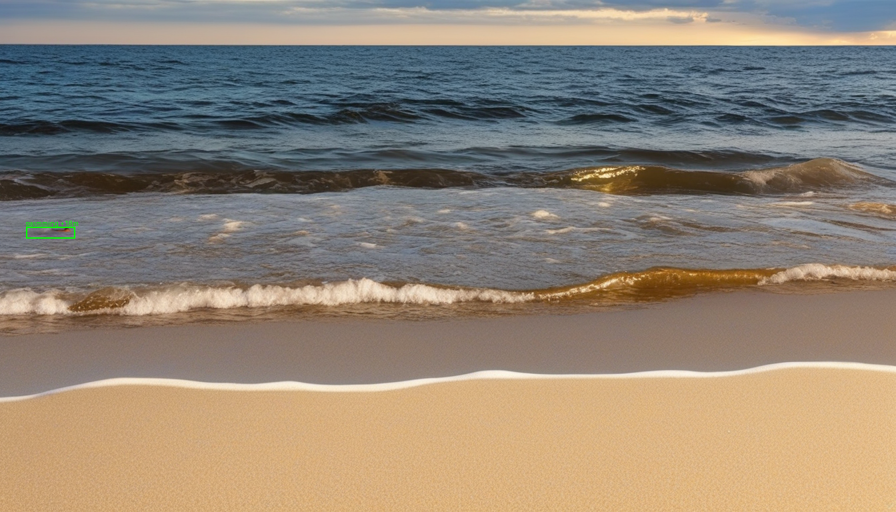

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

img_0001 [rough/golden]: 3 people ['drowning_idr', 'swimming', 'drowning_handsup']


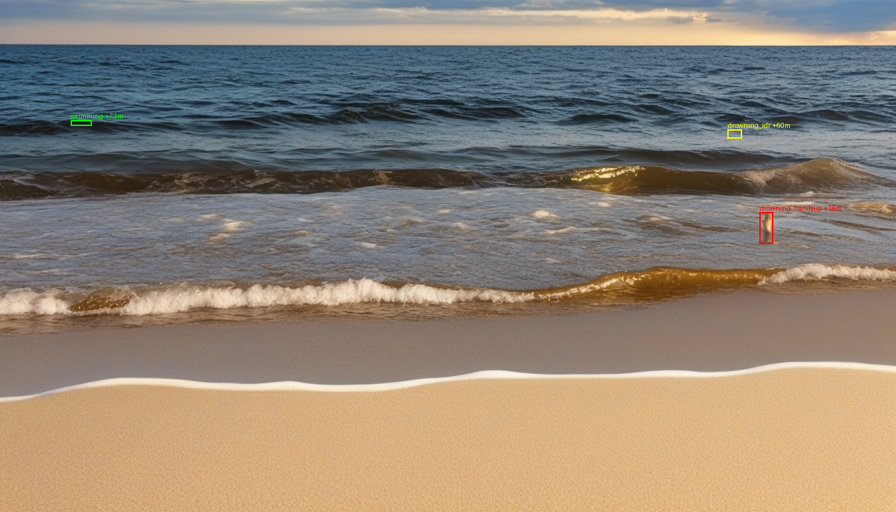

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

img_0002 [waves/overcast]: 4 people ['drowning_handsup', 'drowning_idr', 'swimming', 'swimming']


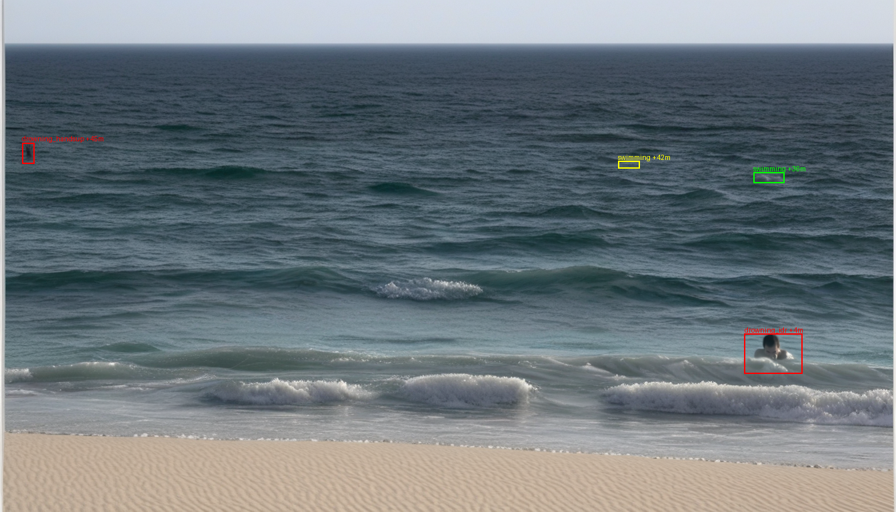

  0%|          | 0/29 [00:00<?, ?it/s]

img_0003 [waves/overcast]: 1 people ['waving']


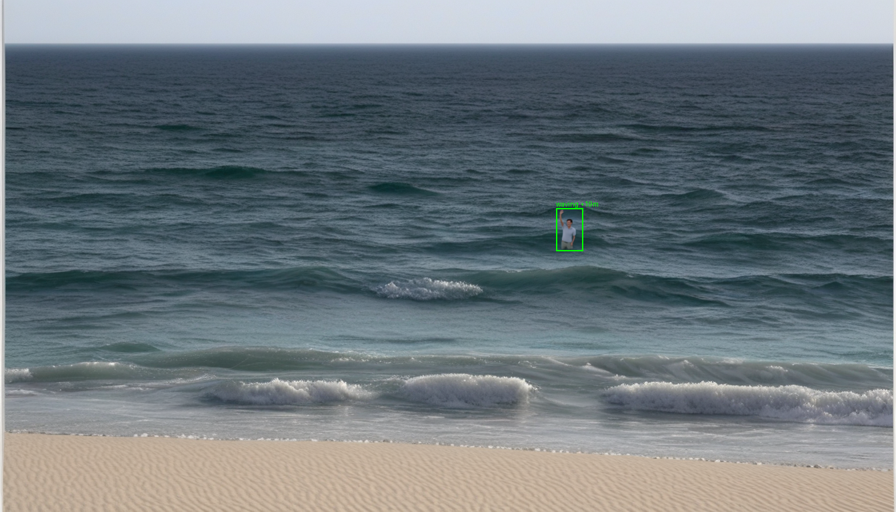

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

  0%|          | 0/29 [00:00<?, ?it/s]

img_0004 [calm/glare]: 4 people ['drowning_handsup', 'drowning_idr', 'waving', 'drowning_idr']


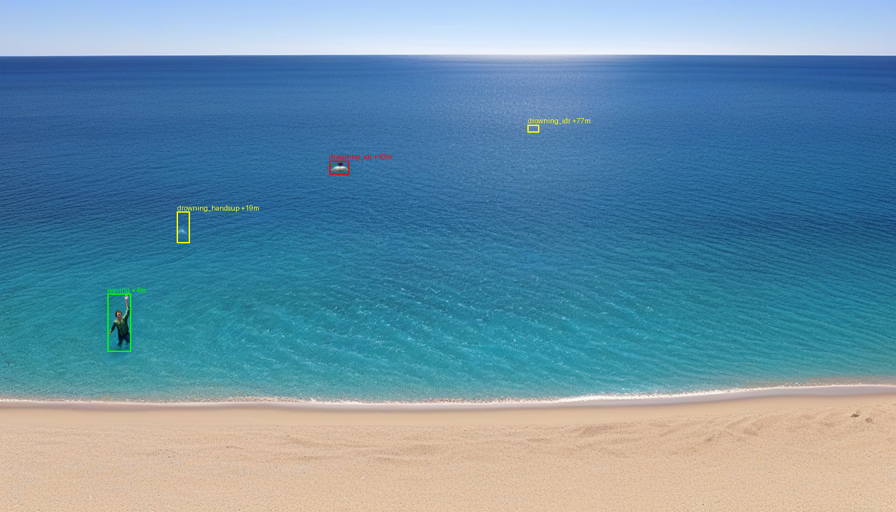

In [15]:
N_IMAGES = 5          # פיילוט
IMAGES_PER_BG = 2
MAX_PEOPLE = 4

FIELDS = ['image', 'bg', 'bg_seed', 'sea', 'light', 'cam_h', 'cam_tilt', 'shore_m', 'person', 'pose', 'label',
          'class_id', 'band', 'from_shore_m', 'dist_m', 'size_px', 'x1', 'y1', 'x2', 'y2', 'bbox_source', 'seed', 'prompt']
csv_path = os.path.join(DIRS['meta'], 'persons.csv')
new_csv = not os.path.exists(csv_path)
bg_meta = json.load(open(os.path.join(DIRS['meta'], 'backgrounds.json')))

bg_files = sorted(f for f in os.listdir(DIRS['backgrounds'])
                  if f in bg_meta and os.path.exists(os.path.join(DIRS['masks'], f)))
img_idx = len([x for x in os.listdir(DIRS['images']) if x.endswith('.png')])
rng = random.Random(123 + img_idx)
rng.shuffle(bg_files)
made = 0

with open(csv_path, 'a', newline='') as fcsv:
    wr = csv.DictWriter(fcsv, FIELDS)
    if new_csv:
        wr.writeheader()
    for bgf in bg_files:
        if made >= N_IMAGES:
            break
        bm = bg_meta[bgf]; cam = bm['cam']; sea, light = bm['sea'], bm['light']
        water = np.array(Image.open(os.path.join(DIRS['masks'], bgf))) > 127
        for rep in range(IMAGES_PER_BG):
            if made >= N_IMAGES:
                break
            full = Image.open(os.path.join(DIRS['backgrounds'], bgf)).convert('RGB')
            people = plan_people(rng, rng.randint(1, MAX_PEOPLE), water, cam)
            if not people:
                print('לא נמצא מקום לאנשים ב-', bgf); break
            name = f'img_{img_idx:04d}'
            lines, rows = [], []
            for j, p in enumerate(people):
                seed = bm['seed'] * 1000 + img_idx * 10 + j
                prompt = POSES[p['pose']]['prompt'] + SUFFIX.format(sea=SEA[sea], light=LIGHT[light])
                full, cx0, cy0, side, out, mb = inpaint_person(full, p, prompt, seed)
                tb = tight_bbox(out, mb)
                k = 1024 / side
                if tb is not None:
                    box, src = [cx0 + tb[0] / k, cy0 + tb[1] / k, cx0 + tb[2] / k, cy0 + tb[3] / k], 'sam'
                else:
                    box, src = p['box'], 'planned'
                box = [max(0, box[0]), max(0, box[1]), min(W, box[2]), min(H, box[3])]
                cid = CLASS_MAP[p['label']]
                lines.append(f"{cid} {(box[0]+box[2])/2/W:.6f} {(box[1]+box[3])/2/H:.6f} "
                             f"{(box[2]-box[0])/W:.6f} {(box[3]-box[1])/H:.6f}")
                rows.append(dict(image=name, bg=bgf, bg_seed=bm['seed'], sea=sea, light=light,
                                 cam_h=round(cam['h'], 3), cam_tilt=round(cam['tilt'], 2), shore_m=round(cam['shore'], 1),
                                 person=j, pose=p['pose'], label=p['label'], class_id=cid, band=p['band'],
                                 from_shore_m=p['from_shore_m'], dist_m=p['dist_m'], size_px=p['size_px'],
                                 x1=round(box[0], 1), y1=round(box[1], 1), x2=round(box[2], 1), y2=round(box[3], 1),
                                 bbox_source=src, seed=seed, prompt=prompt))
            full.save(os.path.join(DIRS['images'], name + '.png'))
            with open(os.path.join(DIRS['labels'], name + '.txt'), 'w') as fl:
                fl.write('\n'.join(lines) + '\n')
            rev = full.copy(); d = ImageDraw.Draw(rev)       # אדום=drowning, ירוק=swimming, צהוב=bbox לא מ-SAM
            for r in rows:
                col = 'yellow' if r['bbox_source'] != 'sam' else ('red' if r['label'] == 'drowning' else 'lime')
                d.rectangle([r['x1'], r['y1'], r['x2'], r['y2']], outline=col, width=2)
                d.text((r['x1'], max(0, r['y1'] - 12)), f"{r['pose']} +{r['from_shore_m']:.0f}m", fill=col)
            rev.save(os.path.join(DIRS['review'], name + '.jpg'), quality=90)
            for r in rows:
                wr.writerow(r)
            fcsv.flush()
            print(f'{name} [{sea}/{light}]: {len(rows)} people', [r['pose'] for r in rows])
            display(rev.resize((896, 512)))
            img_idx += 1
            made += 1

## 7. בדיקה ידנית (חובה!)
עברו על `review/`: נוצר אדם? התנוחה מתאימה לתווית? ה-bbox צמוד? הגודל הגיוני למרחק?
תמונה פגומה → הוסיפו ל-`BAD_IMAGES`. **לא** מסננים לפי "האם YOLO מצא אותו" – זה מטה את הסט למקרים קלים.

In [ ]:
import pandas as pd
BAD_IMAGES = []     # למשל ['img_0003', 'img_0007']

df = pd.read_csv(csv_path)
for name in BAD_IMAGES:
    for folder, ext in [('images', '.png'), ('labels', '.txt'), ('review', '.jpg')]:
        pth = os.path.join(DIRS[folder], name + ext)
        if os.path.exists(pth):
            os.remove(pth)
df = df[~df.image.isin(BAD_IMAGES)]
df.to_csv(csv_path, index=False)

print('תמונות:', df.image.nunique(), '| אנשים:', len(df))
for col in ['band', 'sea', 'light']:
    print(f'\nתווית × {col} (צריך להיות דומה בכל עמודה):')
    print(pd.crosstab(df.label, df[col]))
print('\nמקור bbox:'); print(df.bbox_source.value_counts())

## 8. הערכת המודל
העלו את `best.pt` ל-`drowning_synth/` ב-Drive. אין משקלים, רק דאטה מ-Roboflow? → התא האופציונלי מאמן מודל בסיס.

In [ ]:
# אופציונלי – אימון מודל בסיס על דאטה הבריכות (data.yaml מההורדה של Roboflow)
# base = YOLO('yolo11n.pt')
# base.train(data='/content/drive/MyDrive/pool_dataset/data.yaml', epochs=50, imgsz=640)
# MODEL_PATH = base.trainer.best

In [ ]:
import yaml
from ultralytics import YOLO
MODEL_PATH = os.path.join(BASE, 'best.pt')
model = YOLO(MODEL_PATH)
print('מחלקות המודל:', model.names)
for nm, cid in CLASS_MAP.items():
    ok = nm in str(model.names.get(cid)).lower()
    print(f'CLASS_MAP: {nm} → {cid} = "{model.names.get(cid)}"', '' if ok else '  ⚠️ לבדוק!')

yaml_path = os.path.join(BASE, 'synthetic.yaml')
with open(yaml_path, 'w') as f:
    yaml.safe_dump({'path': BASE, 'train': 'images', 'val': 'images', 'names': model.names}, f)
metrics = model.val(data=yaml_path, split='val')
print('mAP@0.5:', metrics.box.map50, '| mAP@0.5:0.95:', metrics.box.map)

In [ ]:
CONF, IOU_T = 0.25, 0.5

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    u = (a[2]-a[0]) * (a[3]-a[1]) + (b[2]-b[0]) * (b[3]-b[1]) - inter
    return inter / u if u > 0 else 0

df = pd.read_csv(csv_path)
preds = {}
for img in df.image.unique():
    r = model.predict(os.path.join(DIRS['images'], img + '.png'), conf=CONF, verbose=False)[0]
    preds[img] = [(int(c), b.tolist()) for c, b in zip(r.boxes.cls, r.boxes.xyxy)]

def best_iou(row, cls):
    gt = [row.x1, row.y1, row.x2, row.y2]
    return max([iou(gt, b) for c, b in preds[row.image] if c == cls], default=0)

df['detected'] = df.apply(lambda r: best_iou(r, r.class_id) >= IOU_T, axis=1)
df['pred_drowning'] = df.apply(lambda r: best_iou(r, CLASS_MAP['drowning']) >= IOU_T, axis=1)

dr = df[df.label == 'drowning']
print('Recall טובעים – כללי:', round(dr.detected.mean(), 3), f'(n={len(dr)})')
for col in ['band', 'sea', 'light', 'pose']:
    print(f'\nRecall טובעים לפי {col}:')
    print(dr.groupby(col).detected.agg(['mean', 'count']).round(3))
print('\nRecall לפי מרחק מקו המים (מטרים):')
print(dr.groupby(pd.cut(dr.from_shore_m, [0, 10, 20, 40, 60, 80])).detected.agg(['mean', 'count']).round(3))

wv = df[df.pose == 'waving']
print('\nהתרעת שווא על נפנוף שמח (hard negative):', round(wv.pred_drowning.mean(), 3), f'(n={len(wv)})')
df.to_csv(os.path.join(DIRS['meta'], 'eval_results.csv'), index=False)